# 05 · Comparison of the different cases - Figs. 9 and 10

Section 3.6: more available funds allow more interventions, lower objective function values
and larger penalty reductions (relative to the current condition, 73.71 kUSD/y).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from coolingnet import paper_case
from coolingnet.optimization import SolverSettings
from coolingnet.reporting import figures as F
from coolingnet.reporting import paper_reference as REF
from coolingnet.reporting import tables as T
from coolingnet.workflow import PaperPipeline, PipelineConfig

RESULTS_DIR = Path("../results")
FORCE_RESOLVE = False

case = paper_case()
pipeline = PaperPipeline(case, PipelineConfig(results_dir=RESULTS_DIR, force=FORCE_RESOLVE, solver=SolverSettings(name="nlpbb", time_limit_s=900)))
sims = pipeline.run_simulations()
comparison = {"No Budget": pipeline.run_no_budget()}
comparison.update({f"Case {k.replace('budget_', '')}": v for k, v in pipeline.run_budget_cases().items()})
comparison["Case 1"] = pipeline.run_unlimited()["case1"]

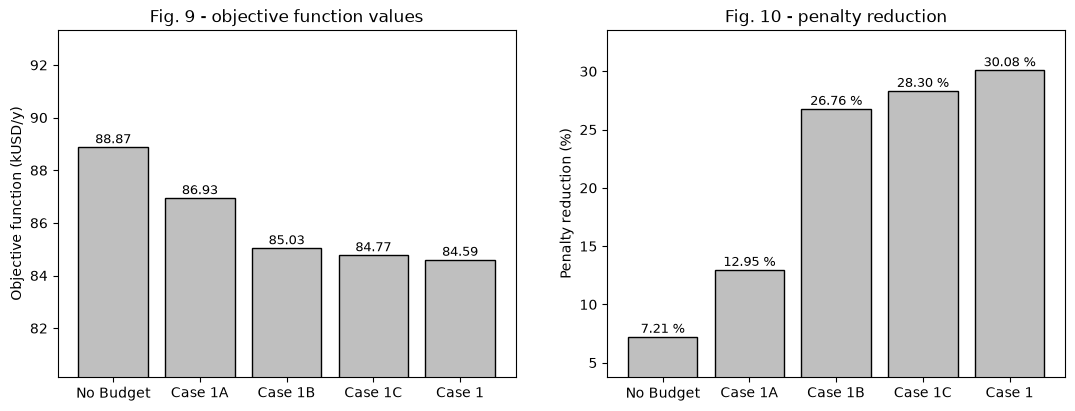

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
F.plot_comparison_bars(comparison, quantity="objective", ax=axes[0], title="Fig. 9 - objective function values")
F.plot_comparison_bars(comparison, quantity="penalty_reduction", reference_penalty=sims["current"].costs["cpen"], ax=axes[1], title="Fig. 10 - penalty reduction")
fig.savefig("../figures/fig09_10_comparison.png", dpi=150, bbox_inches="tight")

In [3]:
ref_pen = sims["current"].costs["cpen"]
pd.DataFrame(
    {
        "objective (kUSD/y) [paper]": pd.Series(REF.FIG9_OBJECTIVE_KUSD),
        "objective (kUSD/y) [this work]": pd.Series({k: v.costs["total_cost"] / 1e3 for k, v in comparison.items()}),
        "penalty reduction (%) [paper]": pd.Series(REF.FIG10_PENALTY_REDUCTION_PCT),
        "penalty reduction (%) [this work]": pd.Series({k: (ref_pen - v.costs["cpen"]) / ref_pen * 100 for k, v in comparison.items()}),
    }
).round(2)

,objective (kUSD/y) [paper],objective (kUSD/y) [this work],penalty reduction (%) [paper],penalty reduction (%) [this work]
No Budget,88.87,88.87,7.21,7.21
Case 1A,86.93,86.93,12.95,12.95
Case 1B,85.04,85.03,26.48,26.76
Case 1C,84.77,84.77,28.30,28.30
Case 1,84.59,84.59,30.08,30.08


In [4]:
T.table_costs(comparison).round(3)

,Pipe (kUSD/y),Pump (kUSD/y),Operating (kUSD/y),Penalty (kUSD/y),Objective (kUSD/y),Budget (kUSD/y),Pump option,Pipes changed,Solver status
Run,,,,,,,,,
No Budget,0.000,0.000,20.473,68.396,88.869,0.000,1,0,optimal
Case 1A,2.577,0.000,20.191,64.166,86.934,2.625,1,2,optimal
Case 1B,0.349,3.417,27.282,53.983,85.030,4.125,4,2,optimal
Case 1C,1.288,3.417,27.212,52.848,84.765,5.250,4,1,optimal
Case 1,2.577,3.417,27.056,51.540,84.591,NaN,4,2,optimal
